In [2]:
from pathlib import Path
import sqlite3
import pandas as pd
import numpy as np

# Project folders
PROJECT_ROOT = Path.cwd().parent

DATA_DIR = PROJECT_ROOT / "data" / "sofie"
OUTPUT_DIR = PROJECT_ROOT / "data" / "processed"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Database path
DB_PATH = DATA_DIR / "sofie_data.db"

# Check that the database exists
print("Database exists:", DB_PATH.exists())
print("Database path:", DB_PATH)


Database exists: True
Database path: c:\Users\leena\OneDrive\Desktop\ev-microgrid-twin\data\sofie\sofie_data.db


In [3]:

# Open database in read-only mode
conn = sqlite3.connect(
    f"file:{DB_PATH.as_posix()}?mode=ro",
    uri=True
)

conn.execute("PRAGMA query_only=ON")

# List available tables
tables = pd.read_sql_query(
    """
    SELECT name
    FROM sqlite_master
    WHERE type='table'
    ORDER BY name
    """,
    conn
)

display(tables)


,name
0,charge_box
1,connector
2,connector_meter_value
3,connector_status
4,logging
5,scn_values
6,transaction_start
7,transaction_stop


In [4]:

# 1. Extract EV charger power readings

query = """
SELECT
    m.value_timestamp AS timestamp,
    cb.charge_box_id AS charger_id,
    m.measurand,
    m.value,
    m.unit
FROM connector_meter_value m

JOIN connector c
    ON c.connector_pk = m.connector_pk

JOIN charge_box cb
    ON cb.charge_box_id = c.charge_box_id

WHERE m.measurand = 'Power.Active.Import'
ORDER BY m.value_timestamp
"""

ev_power = pd.read_sql_query(query, conn)

print("Total charger readings:", len(ev_power))

display(ev_power.head())


Total charger readings: 734500


,timestamp,charger_id,measurand,value,unit
0,2025-12-01 03:15:00.000000,WB4,Power.Active.Import,0.000,W
1,2025-12-01 03:15:00.000000,WB1,Power.Active.Import,0.000,W
2,2025-12-01 03:15:00.000000,WB2,Power.Active.Import,0.000,W
3,2025-12-01 03:15:00.000000,WB3,Power.Active.Import,0.000,W
4,2025-12-01 03:15:00.000000,WB6,Power.Active.Import,0.000,W


In [5]:

# 2. Inspect the extracted data

print("Dataset shape:", ev_power.shape)

print("\nData types:")
print(ev_power.dtypes)

print("\nUnits:")
print(ev_power["unit"].value_counts(dropna=False))

print("\nMissing values:")
print(ev_power.isna().sum())

print("\nMeasurement types:")
print(ev_power["measurand"].value_counts())

print("\nChargers:")
print(ev_power["charger_id"].nunique())


Dataset shape: (734500, 5)

Data types:
timestamp     str
charger_id    str
measurand     str
value         str
unit          str
dtype: object

Units:
unit
W    734500
Name: count, dtype: int64

Missing values:
timestamp     0
charger_id    0
measurand     0
value         0
unit          0
dtype: int64

Measurement types:
measurand
Power.Active.Import    734500
Name: count, dtype: int64

Chargers:
8


In [6]:
# Convert timestamp to datetime
ev_power["timestamp"] = pd.to_datetime(
    ev_power["timestamp"],
    errors="coerce"
)

# Convert power values to numeric
ev_power["value"] = pd.to_numeric(
    ev_power["value"],
    errors="coerce"
)

# Convert power from watts to kilowatts
ev_power["power_kw"] = ev_power["value"] / 1000

# Check the results
print(ev_power.dtypes)
display(ev_power.head())

timestamp     datetime64[us]
charger_id               str
measurand                str
value                float64
unit                     str
power_kw             float64
dtype: object


,timestamp,charger_id,measurand,value,unit,power_kw
0,2025-12-01 03:15:00,WB4,Power.Active.Import,0.0,W,0.0
1,2025-12-01 03:15:00,WB1,Power.Active.Import,0.0,W,0.0
2,2025-12-01 03:15:00,WB2,Power.Active.Import,0.0,W,0.0
3,2025-12-01 03:15:00,WB3,Power.Active.Import,0.0,W,0.0
4,2025-12-01 03:15:00,WB6,Power.Active.Import,0.0,W,0.0


In [7]:
print("Invalid timestamps:", ev_power["timestamp"].isna().sum())
print("Invalid power values:", ev_power["value"].isna().sum())

print("Negative power readings:", (ev_power["power_kw"] < 0).sum())

print("Duplicate readings:", ev_power.duplicated(
    subset=["timestamp", "charger_id", "measurand"]
).sum())

print("\nPower statistics (kW):")
display(ev_power["power_kw"].describe())

Invalid timestamps: 0
Invalid power values: 0
Negative power readings: 0
Duplicate readings: 1325

Power statistics (kW):


count    734500.000000
mean          1.565321
std           1.616440
min           0.000000
25%           0.000000
50%           1.075100
75%           3.367800
max           3.882900
Name: power_kw, dtype: float64

In [8]:
charger_summary = (
    ev_power.groupby("charger_id")
    .agg(
        readings=("power_kw", "count"),
        average_power_kw=("power_kw", "mean"),
        maximum_power_kw=("power_kw", "max")
    )
    .reset_index()
)

display(charger_summary)

,charger_id,readings,average_power_kw,maximum_power_kw
0,WB1,82356,1.669045,3.6893
1,WB2,111275,1.455014,3.8113
2,WB3,76179,1.069607,3.8439
3,WB4,84927,1.586348,3.8571
4,WB5,91418,1.758008,3.8829
5,WB6,44417,1.148362,3.8295
6,WB7,126456,1.899217,3.8576
7,WB8,117472,1.551627,3.7516


In [9]:
# Get all duplicate rows
duplicates = ev_power[
    ev_power.duplicated(
        subset=["timestamp", "charger_id", "measurand"],
        keep=False
    )
].sort_values(["charger_id", "timestamp"])

print("Rows involved in duplicates:", len(duplicates))

# Check whether duplicate groups have different power values
duplicate_summary = (
    duplicates.groupby(["timestamp", "charger_id"])
    .agg(
        number_of_readings=("value", "size"),
        different_values=("value", "nunique")
    )
    .reset_index()
)

print("Duplicate groups:", len(duplicate_summary))
print(
    "Groups with different power values:",
    (duplicate_summary["different_values"] > 1).sum()
)

display(duplicates.head(15))
display(duplicate_summary.head(10))

Rows involved in duplicates: 2440
Duplicate groups: 1115
Groups with different power values: 0


,timestamp,charger_id,measurand,value,unit,power_kw
140184,2026-01-18 13:45:00,WB1,Power.Active.Import,3452.1,W,3.4521
140185,2026-01-18 13:45:00,WB1,Power.Active.Import,3452.1,W,3.4521
140252,2026-01-18 14:00:00,WB1,Power.Active.Import,3472.6,W,3.4726
140253,2026-01-18 14:00:00,WB1,Power.Active.Import,3472.6,W,3.4726
140320,2026-01-18 14:15:00,WB1,Power.Active.Import,3493.3,W,3.4933
140321,2026-01-18 14:15:00,WB1,Power.Active.Import,3493.3,W,3.4933
140392,2026-01-18 14:30:01,WB1,Power.Active.Import,2775.5,W,2.7755
140393,2026-01-18 14:30:01,WB1,Power.Active.Import,2775.5,W,2.7755
140456,2026-01-18 14:45:00,WB1,Power.Active.Import,0.0,W,0.0000
140457,2026-01-18 14:45:00,WB1,Power.Active.Import,0.0,W,0.0000


,timestamp,charger_id,number_of_readings,different_values
0,2025-12-05 03:30:00,WB2,2,1
1,2025-12-05 03:45:00,WB2,2,1
2,2025-12-05 04:00:00,WB2,2,1
3,2025-12-05 04:15:00,WB2,2,1
4,2025-12-05 04:30:00,WB2,2,1
5,2025-12-05 04:45:00,WB2,2,1
6,2025-12-05 05:00:00,WB2,2,1
7,2025-12-05 05:15:00,WB2,2,1
8,2025-12-05 05:30:00,WB2,2,1
9,2025-12-05 05:45:00,WB2,2,1


In [10]:
# Check the date range for each charger
coverage = (
    ev_power.groupby("charger_id")
    .agg(
        first_reading=("timestamp", "min"),
        last_reading=("timestamp", "max"),
        unique_timestamps=("timestamp", "nunique")
    )
    .reset_index()
)

display(coverage)

,charger_id,first_reading,last_reading,unique_timestamps
0,WB1,2025-12-01 03:15:00,2026-06-29 18:45:00,82263
1,WB2,2025-12-01 03:15:00,2026-06-29 18:58:46,111116
2,WB3,2025-12-01 03:15:00,2026-06-29 18:45:00,76078
3,WB4,2025-12-01 03:15:00,2026-06-29 18:45:00,84862
4,WB5,2025-12-03 09:58:02,2026-06-29 18:45:00,91337
5,WB6,2025-12-01 03:15:00,2026-06-29 18:45:00,43816
6,WB7,2025-12-01 03:15:00,2026-06-29 18:45:00,126305
7,WB8,2025-12-01 03:15:00,2026-06-29 18:45:00,117398


In [11]:
ev_power_sorted = ev_power.sort_values(
    ["charger_id", "timestamp"]
).copy()

ev_power_sorted["time_gap_minutes"] = (
    ev_power_sorted.groupby("charger_id")["timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

gap_summary = (
    ev_power_sorted.groupby("charger_id")["time_gap_minutes"]
    .describe()
)

display(gap_summary)

,count,mean,std,min,25%,50%,75%,max
charger_id,,,,,,,,
WB1,82355.0,3.683201,29.572037,0.0,0.5,0.5,0.500000,3934.366667
WB2,111274.0,2.726097,11.523158,0.0,0.5,0.5,0.500000,915.000000
WB3,76178.0,3.981858,13.991696,0.0,0.5,0.5,0.516667,930.000000
WB4,84926.0,3.571698,12.977692,0.0,0.5,0.5,0.500000,915.000000
WB5,91417.0,3.282179,22.259259,0.0,0.5,0.5,0.500000,5671.600000
WB6,44416.0,6.829296,17.718473,0.0,0.5,0.5,15.000000,929.983333
WB7,126455.0,2.398719,10.795376,0.0,0.5,0.5,0.500000,930.000000
WB8,117471.0,2.582169,15.542782,0.0,0.5,0.5,0.500000,2065.300000


In [12]:
# Count duplicate groups with identical and different values
print(
    "Groups with identical values:",
    (duplicate_summary["different_values"] == 1).sum()
)

print(
    "Groups with different values:",
    (duplicate_summary["different_values"] > 1).sum()
)

# Display groups with conflicting values
conflicting_groups = duplicate_summary[
    duplicate_summary["different_values"] > 1
]

display(conflicting_groups.head(10))

Groups with identical values: 1115
Groups with different values: 0


,timestamp,charger_id,number_of_readings,different_values


In [13]:
ev_power_clean = ev_power.drop_duplicates(
    subset=[
        "timestamp",
        "charger_id",
        "measurand",
        "value",
        "unit"
    ]
).copy()

print("Original rows:", len(ev_power))
print("Cleaned rows:", len(ev_power_clean))
print("Rows removed:", len(ev_power) - len(ev_power_clean))

Original rows: 734500
Cleaned rows: 733175
Rows removed: 1325


In [14]:
time_data = (
    ev_power_clean[["timestamp", "charger_id"]]
    .drop_duplicates()
    .sort_values(["charger_id", "timestamp"])
    .copy()
)

time_data["gap_minutes"] = (
    time_data.groupby("charger_id")["timestamp"]
    .diff()
    .dt.total_seconds() / 60
)

print("Time interval distribution:")
display(time_data["gap_minutes"].describe())

print("\nIntervals by charger:")
display(
    time_data.groupby("charger_id")["gap_minutes"]
    .describe()
)

print("\nGaps longer than 15 minutes:")
display(
    time_data[time_data["gap_minutes"] > 15]
    .groupby("charger_id")
    .size()
)

Time interval distribution:


count    733167.000000
mean          3.305346
std          17.289228
min           0.016667
25%           0.500000
50%           0.500000
75%           0.500000
max        5671.600000
Name: gap_minutes, dtype: float64


Intervals by charger:


,count,mean,std,min,25%,50%,75%,max
charger_id,,,,,,,,
WB1,82262.0,3.687365,29.588489,0.016667,0.5,0.5,0.500000,3934.366667
WB2,111115.0,2.729998,11.530938,0.016667,0.5,0.5,0.500000,915.000000
WB3,76077.0,3.987145,14.000228,0.016667,0.5,0.5,0.516667,930.000000
WB4,84861.0,3.574433,12.982284,0.016667,0.5,0.5,0.500000,915.000000
WB5,91336.0,3.285090,22.268912,0.016667,0.5,0.5,0.500000,5671.600000
WB6,43815.0,6.922972,17.821395,0.016667,0.5,0.5,15.000000,929.983333
WB7,126304.0,2.401587,10.801509,0.016667,0.5,0.5,0.500000,930.000000
WB8,117397.0,2.583797,15.547544,0.016667,0.5,0.5,0.500000,2065.300000



Gaps longer than 15 minutes:


charger_id
WB1    738
WB2    802
WB3    830
WB4    855
WB5    792
WB6    896
WB7    847
WB8    803
dtype: int64

In [15]:
# Summarize intervals for each charger
interval_summary = (
    time_data.groupby("charger_id")["gap_minutes"]
    .agg(
        median_interval="median",
        mean_interval="mean",
        maximum_gap="max"
    )
    .reset_index()
)

display(interval_summary)

,charger_id,median_interval,mean_interval,maximum_gap
0,WB1,0.5,3.687365,3934.366667
1,WB2,0.5,2.729998,915.000000
2,WB3,0.5,3.987145,930.000000
3,WB4,0.5,3.574433,915.000000
4,WB5,0.5,3.285090,5671.600000
5,WB6,0.5,6.922972,929.983333
6,WB7,0.5,2.401587,930.000000
7,WB8,0.5,2.583797,2065.300000


In [16]:
# Count gaps longer than different thresholds
gap_counts = []

for charger in time_data["charger_id"].unique():

    charger_data = time_data[
        time_data["charger_id"] == charger
    ]

    gap_counts.append({
        "charger_id": charger,
        "gaps_over_5_min": (charger_data["gap_minutes"] > 5).sum(),
        "gaps_over_15_min": (charger_data["gap_minutes"] > 15).sum(),
        "gaps_over_1_hour": (charger_data["gap_minutes"] > 60).sum()
    })

gap_counts = pd.DataFrame(gap_counts)

display(gap_counts)

,charger_id,gaps_over_5_min,gaps_over_15_min,gaps_over_1_hour
0,WB1,15084,738,69
1,WB2,15449,802,63
2,WB3,16577,830,63
3,WB4,16343,855,63
4,WB5,15683,792,58
5,WB6,17661,896,63
6,WB7,14922,847,65
7,WB8,14481,803,74


In [17]:
# Distribution of intervals
display(
    time_data["gap_minutes"]
    .round(2)
    .value_counts()
    .head(15)
    .rename_axis("interval_minutes")
    .reset_index(name="frequency")
)

,interval_minutes,frequency
0,0.50,504104
1,15.00,112467
2,0.48,34263
3,0.52,32779
4,14.98,5842
5,15.02,5841
6,0.08,1490
7,0.42,1486
8,0.15,1411
9,0.35,1409


In [18]:
time_data["interval_type"] = np.select(
    [
        time_data["gap_minutes"] <= 1,
        time_data["gap_minutes"].between(10, 20),
        time_data["gap_minutes"] > 20
    ],
    [
        "Around 30 seconds",
        "Around 15 minutes",
        "Other / Long gap"
    ],
    default="Other"
)

time_data["month"] = (
    time_data["timestamp"].dt.to_period("M").astype(str)
)

reporting_patterns = (
    time_data.groupby(
        ["charger_id", "month", "interval_type"]
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

display(reporting_patterns)

interval_type,charger_id,month,Around 15 minutes,Around 30 seconds,Other,Other / Long gap
0,WB1,2025-12,2068,3646,10,28
1,WB1,2026-01,2107,3505,12,24
2,WB1,2026-02,2453,7137,17,0
3,WB1,2026-03,2514,11318,19,4
4,WB1,2026-04,1998,11203,19,5
5,WB1,2026-05,1576,16565,17,8
6,WB1,2026-06,2229,13744,34,3
7,WB2,2025-12,1665,15940,23,28
8,WB2,2026-01,1817,13635,24,24
9,WB2,2026-02,2219,14345,21,0


In [19]:
display(
    time_data["interval_type"]
    .value_counts()
    .to_frame("number_of_intervals")
)

,number_of_intervals
interval_type,
Around 30 seconds,606510
Around 15 minutes,125074
Other,1052
Other / Long gap,539


In [20]:
charger_data = ev_power_clean[
    ["timestamp", "charger_id", "power_kw"]
].copy()

charger_data = charger_data.sort_values(
    ["charger_id", "timestamp"]
)

display(charger_data.head())

,timestamp,charger_id,power_kw
1,2025-12-01 03:15:00,WB1,0.0
7,2025-12-01 03:30:00,WB1,0.0
17,2025-12-01 03:45:00,WB1,0.0
21,2025-12-01 04:00:00,WB1,0.0
28,2025-12-01 04:15:00,WB1,0.0


In [21]:
charger_15min = (
    charger_data
    .set_index("timestamp")
    .groupby("charger_id")["power_kw"]
    .resample("15min")
    .mean()
    .reset_index()
)

display(charger_15min.head(15))

,charger_id,timestamp,power_kw
0,WB1,2025-12-01 03:15:00,0.0
1,WB1,2025-12-01 03:30:00,0.0
2,WB1,2025-12-01 03:45:00,0.0
3,WB1,2025-12-01 04:00:00,0.0
4,WB1,2025-12-01 04:15:00,0.0
5,WB1,2025-12-01 04:30:00,0.0
6,WB1,2025-12-01 04:45:00,0.0
7,WB1,2025-12-01 05:00:00,0.0
8,WB1,2025-12-01 05:15:00,0.0
9,WB1,2025-12-01 05:30:00,0.0


In [22]:
missing_summary = (
    charger_15min.groupby("charger_id")
    .agg(
        total_intervals=("power_kw", "size"),
        missing_intervals=("power_kw", lambda x: x.isna().sum()),
        available_intervals=("power_kw", "count")
    )
    .reset_index()
)

missing_summary["missing_percentage"] = (
    missing_summary["missing_intervals"]
    / missing_summary["total_intervals"] * 100
)

display(missing_summary)

,charger_id,total_intervals,missing_intervals,available_intervals,missing_percentage
0,WB1,20223,2989,17234,14.780201
1,WB2,20223,1732,18491,8.564506
2,WB3,20223,1752,18471,8.663403
3,WB4,20223,1708,18515,8.445829
4,WB5,20005,1918,18087,9.587603
5,WB6,20223,1732,18491,8.564506
6,WB7,20223,1755,18468,8.678238
7,WB8,20223,2451,17772,12.119864


In [23]:
charger_pivot = charger_15min.pivot(
    index="timestamp",
    columns="charger_id",
    values="power_kw"
)

charger_pivot["available_chargers"] = (
    charger_pivot.notna().sum(axis=1)
)

display(
    charger_pivot["available_chargers"]
    .value_counts()
    .sort_index()
)

available_chargers
0     1701
1        7
2        1
3        6
4       13
5        5
6       22
7     2451
8    16017
Name: count, dtype: int64

In [24]:
# Create a wide-format dataset
charger_wide = charger_15min.pivot(
    index="timestamp",
    columns="charger_id",
    values="power_kw"
)

# Count how many chargers reported readings
charger_wide["available_chargers"] = (
    charger_wide.notna().sum(axis=1)
)

# Calculate total only when all 8 chargers have readings
charger_wide["total_ev_power_kw"] = (
    charger_wide[
        ["WB1", "WB2", "WB3", "WB4",
         "WB5", "WB6", "WB7", "WB8"]
    ].sum(axis=1, min_count=8)
)

display(charger_wide.head(15))

charger_id,WB1,WB2,WB3,WB4,WB5,WB6,WB7,WB8,available_chargers,total_ev_power_kw
timestamp,,,,,,,,,,
2025-12-01 03:15:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN
2025-12-01 03:30:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN
2025-12-01 03:45:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN
2025-12-01 04:00:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN
2025-12-01 04:15:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN
2025-12-01 04:30:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN
2025-12-01 04:45:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN
2025-12-01 05:00:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN
2025-12-01 05:15:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN


In [25]:
print("Total 15-minute intervals:", len(charger_wide))

print(
    "Intervals with all 8 chargers:",
    (charger_wide["available_chargers"] == 8).sum()
)

print(
    "Intervals with partial readings:",
    (
        (charger_wide["available_chargers"] > 0) &
        (charger_wide["available_chargers"] < 8)
    ).sum()
)

print(
    "Intervals with no readings:",
    (charger_wide["available_chargers"] == 0).sum()
)

print("\nTotal EV power statistics (kW):")
display(charger_wide["total_ev_power_kw"].describe())

Total 15-minute intervals: 20223
Intervals with all 8 chargers: 16017
Intervals with partial readings: 2505
Intervals with no readings: 1701

Total EV power statistics (kW):


count    16017.000000
mean         2.196347
std          4.210803
min          0.000000
25%          0.000000
50%          0.000000
75%          3.322361
max         22.382261
Name: total_ev_power_kw, dtype: float64

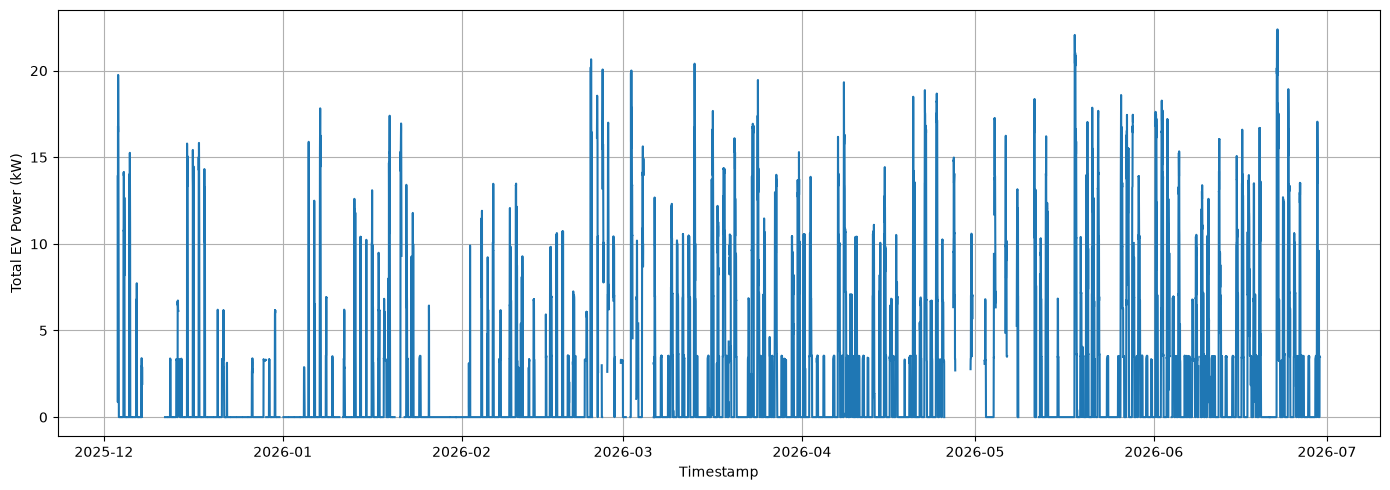

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    charger_wide.index,
    charger_wide["total_ev_power_kw"]
)

plt.xlabel("Timestamp")
plt.ylabel("Total EV Power (kW)")
plt.grid(True)
plt.tight_layout()
plt.show()

In [27]:
# Get individual charger columns
charger_columns = [
    "WB1", "WB2", "WB3", "WB4",
    "WB5", "WB6", "WB7", "WB8"
]

# Sum the available readings, even if some chargers are missing
charger_wide["observed_ev_power_kw"] = (
    charger_wide[charger_columns].sum(
        axis=1,
        min_count=1
    )
)

# Identify whether all chargers reported
charger_wide["data_complete"] = (
    charger_wide["available_chargers"] == 8
)

# Calculate energy for each 15-minute interval
charger_wide["observed_ev_energy_kwh"] = (
    charger_wide["observed_ev_power_kw"] * 0.25
)

display(charger_wide.head(15))

charger_id,WB1,WB2,WB3,WB4,WB5,WB6,WB7,WB8,available_chargers,total_ev_power_kw,observed_ev_power_kw,data_complete,observed_ev_energy_kwh
timestamp,,,,,,,,,,,,,
2025-12-01 03:15:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN,0.0,False,0.0
2025-12-01 03:30:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN,0.0,False,0.0
2025-12-01 03:45:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN,0.0,False,0.0
2025-12-01 04:00:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN,0.0,False,0.0
2025-12-01 04:15:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN,0.0,False,0.0
2025-12-01 04:30:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN,0.0,False,0.0
2025-12-01 04:45:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN,0.0,False,0.0
2025-12-01 05:00:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN,0.0,False,0.0
2025-12-01 05:15:00,0.0,0.0,0.0,0.0,NaN,0.0,0.0,0.0,7,NaN,0.0,False,0.0


In [28]:
print("Complete intervals:")
print(charger_wide["data_complete"].sum())

print("\nPartial intervals:")
print(
    (
        (charger_wide["available_chargers"] > 0) &
        (charger_wide["available_chargers"] < 8)
    ).sum()
)

print("\nIntervals with no readings:")
print(
    (charger_wide["available_chargers"] == 0).sum()
)

print("\nObserved EV power statistics:")
display(
    charger_wide["observed_ev_power_kw"].describe()
)

Complete intervals:
16017

Partial intervals:
2505

Intervals with no readings:
1701

Observed EV power statistics:


count    18522.000000
mean         2.068053
std          4.076760
min          0.000000
25%          0.000000
50%          0.000000
75%          3.279948
max         22.382261
Name: observed_ev_power_kw, dtype: float64

In [29]:
# Reset timestamp index
charger_output = charger_wide.reset_index()

# Save processed data
output_path = OUTPUT_DIR / "ev_charger_15min.csv"

charger_output.to_csv(output_path, index=False)

print("Saved to:", output_path)
print("Dataset shape:", charger_output.shape)

Saved to: c:\Users\leena\OneDrive\Desktop\ev-microgrid-twin\data\processed\ev_charger_15min.csv
Dataset shape: (20223, 14)
